<a href="https://colab.research.google.com/github/andysanchez1403-droid/SIMULACION-II/blob/main/AJUSTE_DE_PAR%C3%81METROS_ISR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PROYECTO: AJUSTE DE PARÁMETROS DEL MODELO SIR**




1.   Graficar datos.
2.   Programación de solucón numérica del modelo SIR, con parametros libres.
3.   Plantear un ajuste por mínimos cuadrados , X(a,b)
4.   Usar el método MCMC (Metroplis-Hastings) para optimizar X.
5.   Replantear con pyMC en el enfoque bayesiano.



$\frac{dS}{dt}= -aSI$

$\frac{dI}{dt}= aSI - bI$

$\frac{dR}{dt}= bI$

#**1) Graficar datos**

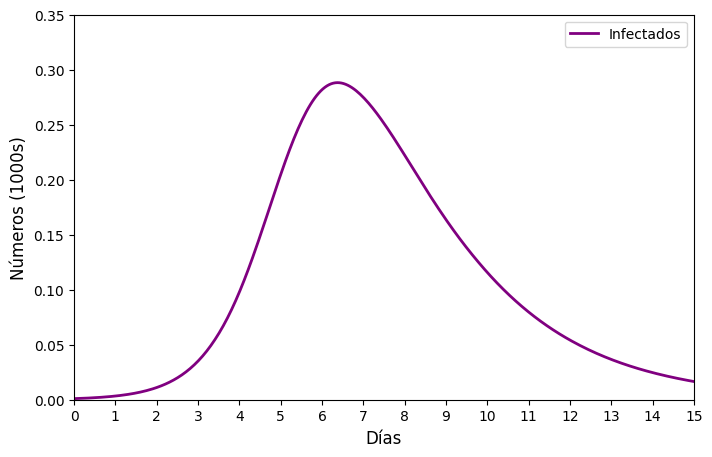

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# 1. Parámetros y condiciones iniciales
N = 763
I = 1
S = N - I
R = 0

a = 0.00218
b = 0.4485


# 2. Definición del modelo SIR
def sir_model(t, y):
    S, I, R = y
    return [-a * S * I, a * S * I - b * I, b * I]


# 3. Solución numérica para 15 días
t_eval = np.linspace(0, 15, 300)
sol = solve_ivp(sir_model, (0, 15), [S0, I0, R0], t_eval=t_eval)

# 4. Generación de la gráfica (0 a 15 días)
plt.figure(figsize=(8, 5))
plt.plot(sol.t, sol.y[1] / 1000, color="purple", label="Infectados", linewidth=2)

plt.xlim(0, 15)  # Eje X de 0 a 15
plt.ylim(0, 0.35)  # Eje Y en el pico
plt.xticks(range(0, 16, 1))  # Marcas de 1 en 1 día
plt.yticks(np.arange(0.0, 0.4, 0.05))


plt.xlabel("Días", fontsize=12)
plt.ylabel("Números (1000s)", fontsize=12)
plt.legend(loc="upper right", frameon=True)

plt.show()

# **2) Programación de solución numérica del modelo**

     t  I(t)
0    0     1
1    1     3
2    2     6
3    3    25
4    4    73
5    5   222
6    6   294
7    7   258
8    8   237
9    9   191
10  10   125
11  11    69
12  12    27
13  13    11
14  14     4


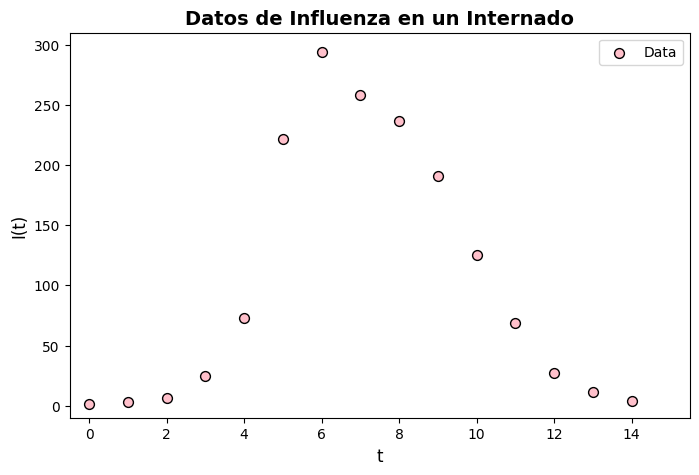

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Definición de los datos
t = list(range(15))
I = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]

# 2. Creación del DataFrame de Pandas
df = pd.DataFrame({"t": t, "I(t)": I})
print(df)

# 3. Generación de la gráfica de puntos
plt.figure(figsize=(8, 5))
plt.scatter(
    t,
    I,
    color="pink",
    edgecolor="black",
    s=50,
    label="Data",
    zorder=3,
)

# Configuración de ejes y estilos
plt.xlabel("t", fontsize=12)
plt.ylabel("I(t)", fontsize=12)
plt.xlim(-0.5, 15.5)
plt.ylim(-10, 310)
plt.xticks(range(0, 16, 2))
plt.legend(loc="upper right", frameon=True)
plt.grid(False)


plt.title("Datos de Influenza en un Internado", fontsize=14, fontweight="bold")
plt.show()

# **3) AJUSTAR POR MÍNIMOS CUADRADOS**

In [4]:
from scipy.optimize import minimize
from scipy.integrate import solve_ivp
import numpy as np

# Datos anteriores
# Valores de infectados de acuerdo a la gráfica: I = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]
t_data = np.array(list(range(15)))
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# Función de Suma de Errores Cuadráticos (SSE)
def sse_func(params):
    a_val, b_val = params

    def model(t, y):
        S, I, R = y
        return [-a_val * S * I, a_val * S * I - b_val * I, b_val * I]

    # Resolver la ED con los parámetros candidatos
    sol = solve_ivp(model, (0, 14), [762, 1, 0], t_eval=t_data)

    # Calcular residuo cuadrático sobre I(t)
    if sol.success:
        I_pred = sol.y[1]
        return np.sum((I_data - I_pred)**2)
    return 1e10

# Optimización por Mínimos Cuadrados
initial_guess = [0.00218, 0.4485]
res = minimize(sse_func, initial_guess, bounds=[(1e-5, 1), (1e-5, 1)])
a_ls, b_ls = res.x

print(f"Parámetros de Mínimos Cuadrados:")
print(f"a = {a_ls:.6f}, b = {b_ls:.6f}")

Parámetros de Mínimos Cuadrados:
a = 0.002180, b = 0.445534


# **4)Optimización con Metropolis-Hastings**

In [5]:
def log_likelihood(params):
    a_val, b_val = params
    if a_val <= 0 or b_val <= 0:
        return -np.inf

    def model(t, y):
        S, I, R = y
        return [-a_val * S * I, a_val * S * I - b_val * I, b_val * I]

    sol = solve_ivp(model, (0, 14), [762, 1, 0], t_eval=t_data)
    if not sol.success:
        return -np.inf

    I_pred = sol.y[1]
    sigma = 10.0  # Desviación estimada de los errores
    return -0.5 * np.sum(((I_data - I_pred) / sigma)**2)

# MCMC Metropolis-Hastings
num_samples = 5000
chain_params = np.zeros((num_samples, 2))
current = np.array([0.002, 0.4])
chain_params[0] = current

for t in range(1, num_samples):
    proposal = current + np.random.normal(0, [0.00005, 0.005])
    log_alpha = log_likelihood(proposal) - log_likelihood(current)

    if np.log(np.random.uniform(0, 1)) < log_alpha:
        current = proposal

    chain_params[t] = current

burn_in_sir = 1000
a_mcmc = np.mean(chain_params[burn_in_sir:, 0])
b_mcmc = np.mean(chain_params[burn_in_sir:, 1])

print(f"Parámetros estimados (Metropolis-Hastings MCMC):")
print(f"a = {a_mcmc:.6f}, b = {b_mcmc:.6f}")

Parámetros estimados (Metropolis-Hastings MCMC):
a = 0.002181, b = 0.445610


# **5) Enfoque Bayesiano**

In [7]:
import pymc as pm

# Definición del modelo Bayesiano con PyMC
with pm.Model() as modelo_sir_pymc:
    # Priores para los parámetros a y b
    a_prior = pm.Uniform('a', lower=0.0001, upper=0.01)
    b_prior = pm.Uniform('b', lower=0.1, upper=1.0)
    sigma_prior = pm.HalfNormal('sigma', sigma=20)

    # Muestreo Bayesiano (se agrega target_accept para evitar divergencias)
    datos_inferencia = pm.sample(draws=1000, tune=1000, target_accept=0.95, return_inferencedata=True)

# Resumen de resultados
pm.summary(datos_inferencia, var_names=['a', 'b'])

Output()

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.005,0.003,0.0,0.01,0.000,0.000,1264.0,988.0,1.0
b,0.545,0.265,0.1,0.94,0.008,0.004,1097.0,1041.0,1.0
